# NB2 — Time base, quality control, 15-min panel, events and donor sets

Guide §2 preprocessing steps 1–7; D08, D12, D13, D18, D27, D28. Reads `results/nb1_audit/`; writes `results/nb2_panel/` all-or-nothing. Nothing is tuned here.

In [1]:
import sys, time, json
from pathlib import Path
import numpy as np, pandas as pd
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == 'notebooks' else ROOT
sys.path.insert(0, str(ROOT / 'src'))
from pvcold import config as C, audit as A, prep as P, io_hkust as io
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
t0 = time.time()
nb1 = C.RESULTS / 'nb1_audit'
inv = pd.read_csv(nb1 / 'units_inverters.csv'); st = pd.read_csv(nb1 / 'units_stations.csv')
mc = pd.read_csv(nb1 / 'metadata_check.csv'); starts_nb1 = pd.read_csv(nb1 / 'start_dates.csv')
nb1_sum = json.loads((nb1 / 'summary.json').read_text())
ALT = nb1_sum['campus_altitude_m']
units = P.unit_table(inv, st, mc)
print(len(units), 'units |', int(units.flat.sum()), 'flat |', int(units.metadata_error.sum()), 'metadata errors')
units[['station', 'model', 'AC_kW', 'AC_source', 'DC_kWp', 'DC_AC', 'metadata_error', 'tilt', 'azimuth_brick']].round(3)

44 units | 31 flat | 3 metadata errors


,station,model,AC_kW,AC_source,DC_kWp,DC_AC,metadata_error,tilt,azimuth_brick
unit,,,,,,,,,
Indoor Sports Centre_Inverter,Indoor_Sport_Center,Sunny_Tripower_STP_10_0,33.3,station rating 33.3 kW (= SE33_3K); model stri...,43.800,1.315,True,10deg,0/180deg
LSK North_Inverter,LSK_North,SolarEdge_SE55K,55.0,model name,66.300,1.205,False,10deg,10/-153deg
LSK South_Inverter,LSK_South,SolarEdge_SE25K,25.0,model name,28.080,1.123,False,0deg,0deg
Library_Inverter_1,Library,SolarEdge SE50K,50.0,model name,57.720,1.154,False,10deg,Mixed
Library_Inverter_2,Library,SolarEdge SE50K,50.0,model name,56.240,1.125,False,10deg,Mixed
Library_Inverter_3,Library,SolarEdge SE50K,50.0,model name,56.240,1.125,False,10deg,Mixed
SQ1_Inverter,SQ1,SolarEdge_SE27_6K,27.6,model name,34.320,1.243,False,0deg,0deg
SQ2_Inverter,SQ2,SolarEdge_SE33_3K,33.3,model name,33.540,1.007,False,0deg,0deg
SQ3_Inverter,SQ3,SolarEdge_SE33_3K,33.3,model name,35.880,1.077,False,0deg,0deg


## 1. 5-min power and the time label (step 1)
The label convention is fixed by the shift that maximises the correlation between flat-roof fleet power and Ineichen clear-sky GHI on the 30 clearest, smoothest days. A shift of +2.5 min means the 5-min value is the mean of the interval that starts at its stamp. The same test on the 15-min site files gives their offset.

In [2]:
P5raw = P.load_power_5min(units.index)
geo_nom = P.geometry(P5raw.index, 2.5, ALT)
flat = units.index[units.flat & ~units.metadata_error]
y5 = P5raw[flat].div(units.loc[flat, 'AC_kW'] * 1000, axis=1)
y_fleet = y5.median(axis=1); n_flat = y5.notna().sum(axis=1)
days = P.clear_days(y_fleet, geo_nom['Gt'], 30, n_flat)
curve_inv = P.label_offset(y_fleet, days, ALT)
d_inv = float(curve_inv.loc[curve_inv['corr'].idxmax(), 'shift_min'])
print(len(flat), 'flat units;', len(days), 'clear days from', min(days).date(), 'to', max(days).date())
print('inverter files: best shift %+.1f min (corr %.5f)' % (d_inv, curve_inv['corr'].max()))

31 flat units; 30 clear days from 2021-07-09 to 2023-08-03
inverter files: best shift +3.0 min (corr 0.99029)


In [3]:
site_flat = [s for s in units.loc[flat, 'station'].unique() if (units.station == s).sum() == 1]
smap = st.set_index('station')['site_file_15min']
ys = {}
for s in site_flat:
    if isinstance(smap.get(s), str):
        ser = P.load_site_15min(smap[s])
        ys[s] = ser / (units.loc[units.station == s, 'AC_kW'].iloc[0] * 1000)
ys = pd.DataFrame(ys)
ys = ys[(ys.index.hour >= 6) & (ys.index.hour < 18)]
curve_site = P.label_offset(ys.median(axis=1), days, ALT)
d_site = float(curve_site.loc[curve_site['corr'].idxmax(), 'shift_min'])
raw_shift = d_site - 5 - d_inv
SITE_SHIFT_SLOTS = int(np.round(raw_shift / 15))
print(len(ys.columns), 'single-inverter flat site files | site best shift %+.1f min' % d_site)
print('site stamp -> inverter slot: %+.1f min, i.e. %d slot(s) of 15 min (residual %+.1f min)' % (
      raw_shift, SITE_SHIFT_SLOTS, raw_shift - 15 * SITE_SHIFT_SLOTS))

24 single-inverter flat site files | site best shift +11.0 min
site stamp -> inverter slot: +3.0 min, i.e. 0 slot(s) of 15 min (residual +3.0 min)


## 2. Geometry at the effective times, and quality control at 5 min (steps 2 and 4)
Flags: night power, negative power, frozen values (constant for 1 h or more in daylight), y > 1.05, outage (zero power while the crude fleet index exceeds 0.3). Flagged values are kept and marked, not deleted; negative and night values are set to missing.

In [4]:
geo5 = P.geometry(P5raw.index, d_inv, ALT)
P5, F5, k_crude = P.qc_5min(P5raw, units['AC_kW'], geo5)
dl = (geo5['Gt'] > 0.05).to_numpy()
qc = pd.DataFrame({name: ((F5[dl] & bit) > 0).sum() / P5raw[dl].notna().sum() for bit, name in P.FLAG_NAMES.items()})
qc['valid_share_daylight'] = P5raw[dl].notna().mean()
print('flag shares over daylight 5-min values (median / max across units):')
print(qc.agg(['median', 'max']).T.round(4).to_string())
qc.sort_values('over_limit', ascending=False).head(8).round(4)

flag shares over daylight 5-min values (median / max across units):
                      median     max
night                 0.0000  0.0000
negative              0.0000  0.0000
frozen                0.0000  0.0000
over_limit            0.0000  0.0115
outage                0.0002  0.0599
valid_share_daylight  0.8023  0.9646


,night,negative,frozen,over_limit,outage,valid_share_daylight
Zone A7_Inverter,0.0,0.0,0.0,0.0115,0.0004,0.7636
UG Hall2 RF_Inverter,0.0,0.0,0.0,0.0025,0.0051,0.9063
SQ Apartment37-48_Inverter,0.0,0.0,0.0,0.0005,0.0001,0.8845
Zone L2_Inverter,0.0,0.0,0.0,0.0002,0.0001,0.5016
SQ Apartment25-36_Inverter,0.0,0.0,0.0,0.0000,0.0003,0.8868
SQ Apartment13-24_Inverter,0.0,0.0,0.0,0.0000,0.0012,0.8914
Library_Inverter_2,0.0,0.0,0.0,0.0000,0.0004,0.5665
Zone A2_Inverter_3,0.0,0.0,0.0,0.0000,0.0131,0.2350


## 3. 15-min panel (steps 3, 5, 6)

In [5]:
P15, F15, N15 = P.aggregate_15(P5, F5)
geo15 = P.geometry(P15.index, 5 + d_inv, ALT)
y15 = P15.div(units['AC_kW'] * 1000, axis=1)
clipped = y15 >= C.CLIP_THRESHOLD
dl15 = geo15['Gt'] > 0.05
print('15-min slots:', len(P15), '| valid share (daylight, after each unit starts): %.3f' % (
      P15[dl15].notna().sum().sum() / P15[dl15].notna().cummax().sum().sum()))
print('clipped share of valid daylight slots: median %.4f, max %.4f' % (
      (clipped[dl15].sum() / P15[dl15].notna().sum()).median(), (clipped[dl15].sum() / P15[dl15].notna().sum()).max()))

15-min slots: 46800 | valid share (daylight, after each unit starts): 0.961
clipped share of valid daylight slots: median 0.0025, max 0.0330


## 4. Start dates (step 7): first row vs the 70% rule

In [6]:
units['first_row'] = P15.apply(lambda s: s.first_valid_index().normalize())
units['rule_start'] = pd.to_datetime([P.rule_start(P15[u], units.loc[u, 'AC_kW'], geo15['Gt']) for u in units.index])
units['rule_minus_first_days'] = (units['rule_start'] - units['first_row']).dt.days
print('rule start later than the first row by: ', units['rule_minus_first_days'].value_counts().sort_index().to_dict())
units.loc[units['rule_minus_first_days'] > 0, ['first_row', 'rule_start', 'rule_minus_first_days']]

rule start later than the first row by:  {0: 39, 1: 4, 8: 1}


,first_row,rule_start,rule_minus_first_days
unit,,,
Zone A2_Inverter_2,2023-05-16,2023-05-24,8
Zone A2_Inverter_3,2023-05-16,2023-05-17,1
Zone A7_Inverter,2021-10-09,2021-10-10,1
Zone D_Inverter_1,2022-12-03,2022-12-04,1
Zone D_Inverter_2,2022-01-19,2022-01-20,1


## 5. Events, targets, donors and eligibility (D08, D27, D28)
Event starts are the approved observed starts; validation units start at their first row. A donor started (70% rule) at least 14 full days before the event and has data in the 7 days before it. The drift boundary here is the provisional NB1 date; NB3 fixes the final one (D10).

In [7]:
boundary = pd.Timestamp(nb1_sum['sensor_change_points_audit']['ratio_sensor_fleet']['date'])
st_first = starts_nb1.set_index('station')
rows, targets, donor_rows = [], {}, []
for ev in P.EVENTS:
    name, set_, start, target = ev
    if isinstance(target, list):
        own, source = list(target), 'inverter'
    else:
        own = list(target[2] or []) + P.EXTRA_OWN_UNITS.get(name, [])
        source = 'site then inverter' if target[2] else 'site (station level)'
    station = units.loc[own[0], 'station'] if own else st.set_index('site_file_15min').get('station', {}).get(target[1])
    if station is None or (isinstance(station, float)):
        station = st.loc[st.site_file_15min == target[1], 'station'].iloc[0]
    start = pd.Timestamp(start) if start else units.loc[own[0], 'first_row']
    tgt = P.event_target(ev, P15, SITE_SHIFT_SLOTS)
    targets[name] = tgt / 1000.0
    ac = float(units.loc[own, 'AC_kW'].sum()); dc = float(units.loc[own, 'DC_kWp'].sum())
    dn = P.donors_at(start, units, set(own), P15)
    donor_rows += [{'event': name, 'donor': d} for d in dn]
    s1 = st_first.loc[station] if station in st_first.index else None
    rows.append({'event': name, 'set': set_, 'station': station, 'units': '+'.join(own), 'target_source': source,
                 'start': start.date(), 'AC_kW': ac, 'DC_kWp': dc, 'DC_AC': dc / ac,
                 'in_prior_test': bool(units.loc[own, 'in_prior_test'].all()),
                 'tilt': units.loc[own[0], 'tilt'], 'azimuth_brick': units.loc[own[0], 'azimuth_brick'],
                 'connection_date': units.loc[own[0], 'connection_date'],
                 'first_inverter_row': units.loc[own, 'first_row'].min().date(),
                 'first_site_row': s1['site_first_row'] if s1 is not None else None,
                 'rule_start_target': P.rule_start(tgt, ac, geo15['Gt']),
                 'n_donors': len(dn), 'valid_days_90': P.valid_days(tgt, start, geo15['Gt']),
                 'sensor_period_provisional': 'drifted' if P.drifted(start, boundary) else 'stable'})
events = pd.DataFrame(rows)
events['gap_days_connection'] = (pd.to_datetime(events['start']) - pd.to_datetime(events['connection_date'])).dt.days
events['eligible'] = (events.n_donors >= C.MIN_DONORS) & (events.valid_days_90 >= C.MIN_VALID_DAYS_IN_90)
targets = pd.DataFrame(targets)
print(events.groupby('set').agg(n=('event', 'size'), eligible=('eligible', 'sum'), min_donors=('n_donors', 'min')).to_string())
print('scored by provisional sensor period:', events[events.set == 'scored'].sensor_period_provisional.value_counts().to_dict())
events[['event', 'set', 'start', 'target_source', 'AC_kW', 'DC_AC', 'in_prior_test', 'n_donors', 'valid_days_90',
        'sensor_period_provisional', 'rule_start_target', 'gap_days_connection', 'eligible']].round(3)

              n  eligible  min_donors
set                                  
scored       13        13          20
sensitivity   4         4          28
validation   10        10           8
scored by provisional sensor period: {'stable': 8, 'drifted': 5}


,event,set,start,target_source,AC_kW,DC_AC,in_prior_test,n_donors,valid_days_90,sensor_period_provisional,rule_start_target,gap_days_connection,eligible
0,SQ Block S,scored,2021-10-05,inverter,33.3,0.986,True,20,88,stable,2021-10-05,48,True
1,Zone A5,scored,2021-10-05,inverter,17.0,1.193,True,20,88,stable,2021-10-05,3,True
2,SQ Block R,scored,2021-10-06,inverter,33.3,1.140,True,20,88,stable,2021-10-06,49,True
3,Zone A7,scored,2021-10-09,inverter,10.0,1.278,True,20,88,stable,2021-10-10,-30,True
4,Zone A6,scored,2021-10-14,inverter,50.0,1.295,True,20,88,stable,2021-10-14,75,True
5,Zone J2,scored,2021-11-13,site then inverter,50.0,1.278,True,25,73,stable,2021-11-13,-18,True
6,Indoor Sports Centre,scored,2021-11-17,inverter,33.3,1.315,False,27,80,stable,2021-11-17,-14,True
7,Zone D,scored,2022-01-19,site (station level),83.3,1.133,False,31,89,stable,2022-01-20,49,True
8,UG Hall8,scored,2023-01-05,inverter,25.0,1.030,True,38,78,drifted,2023-01-05,-55,True
9,UG Hall9,scored,2023-02-11,inverter,25.0,1.079,True,39,87,drifted,2023-02-11,-18,True


## 6. Hidden-unit test bed (D18)
Pseudo-starts on 1 April 2022 (stable) and 1 April 2023 (drifted): the same season in both windows, so the comparison is not a season effect. Mature units only (online at least 90 days before), with at least 30 valid days in the 90-day window; units still inside their own real event window are left out. Stations go to 5 groups balanced by unit count (seeded).

In [8]:
ev_units = {}
for _, r in events[events.set != 'validation'].iterrows():
    for u in r['units'].split('+'):
        if u: ev_units[u] = pd.Timestamp(r['start']) + pd.Timedelta(days=90)
units['event_window_end'] = pd.Series(ev_units).reindex(units.index)
tb = P.pseudo_testbed(units, P15, geo15['Gt'], set(ev_units))
print(tb.groupby('date').agg(units=('unit', 'size'), stations=('station', 'nunique')).to_string())
print(tb.groupby(['date', 'group']).size().unstack().to_string())

            units  stations
date                       
2022-04-01     31        29
2023-04-01     38        33
group       1  2  3  4  5
date                     
2022-04-01  5  5  8  6  7
2023-04-01  8  8  8  7  7


## 7. Draft figures: Fig. 1 (timeline of starts) and the time-label curves

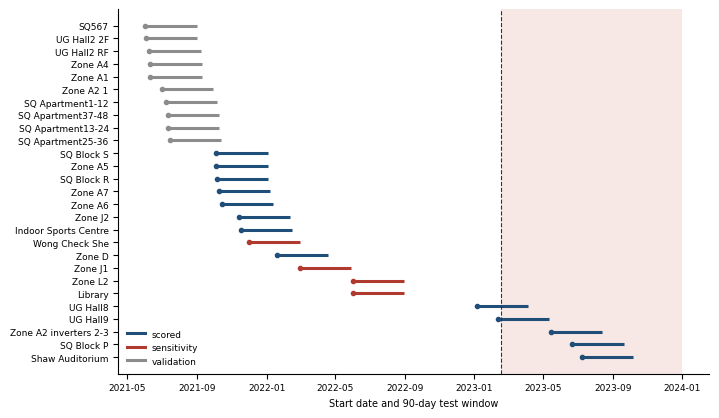

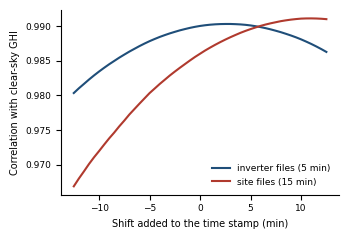

In [9]:
import matplotlib.pyplot as plt
A._style()
ev = events.copy(); ev['start'] = pd.to_datetime(ev['start'])
ev = ev.sort_values('start').reset_index(drop=True)
colors = {'scored': '#1f4e79', 'sensitivity': '#b03a2e', 'validation': '0.55'}
f1, ax = plt.subplots(figsize=(7.2, 4.2))
ax.axvspan(boundary, pd.Timestamp('2024-01-01'), color='#f2d7d5', alpha=0.6, lw=0)
for i, r in ev.iterrows():
    ax.plot([r.start, r.start + pd.Timedelta(days=90)], [i, i], color=colors[r.set], lw=2.2, solid_capstyle='butt')
    ax.plot(r.start, i, 'o', ms=3, color=colors[r.set])
ax.set_yticks(range(len(ev))); ax.set_yticklabels(ev.event)
ax.invert_yaxis(); ax.axvline(boundary, color='0.2', ls='--', lw=0.8)
for s, c in colors.items():
    ax.plot([], [], color=c, lw=2.2, label=s)
ax.legend(frameon=False, loc='lower left'); ax.set_xlabel('Start date and 90-day test window')
f1.tight_layout()
f2, ax2 = plt.subplots(figsize=(3.5, 2.4))
ax2.plot(curve_inv.shift_min, curve_inv['corr'], color='#1f4e79', label='inverter files (5 min)')
ax2.plot(curve_site.shift_min, curve_site['corr'], color='#b03a2e', label='site files (15 min)')
ax2.set_xlabel('Shift added to the time stamp (min)'); ax2.set_ylabel('Correlation with clear-sky GHI')
ax2.legend(frameon=False); f2.tight_layout()

## 8. Outputs (all-or-nothing)

In [10]:
summary = {
    'notebook': 'NB2_preprocessing_events', 'environment': A.versions(), 'runtime_s': round(time.time() - t0, 1),
    'label_shift_inverter_min': d_inv, 'label_shift_site_min': d_site, 'site_shift_slots': SITE_SHIFT_SLOTS,
    'clear_days': [str(d.date()) for d in days], 'n_flat_units': int(len(flat)),
    'qc_flag_share_median': qc.median().round(5).to_dict(), 'qc_flag_share_max': qc.max().round(5).to_dict(),
    'slots_15min': int(len(P15)), 'provisional_boundary': str(boundary.date()),
    'events_by_set': events.groupby('set').size().to_dict(),
    'eligible_by_set': events.groupby('set')['eligible'].sum().astype(int).to_dict(),
    'scored_by_period': events[events.set == 'scored'].sensor_period_provisional.value_counts().to_dict(),
    'testbed_units_by_date': tb.groupby('date').size().rename(index=str).to_dict(),
    'ac_corrections': {k: v[1] for k, v in P.AC_CORRECTIONS.items()},
}
u_out = units.copy(); u_out.index.name = 'unit'
tables = {'units': u_out.reset_index(), 'events': events, 'donors': pd.DataFrame(donor_rows), 'testbed': tb,
          'qc_flag_shares': qc.reset_index(names='unit'), 'label_offset_inverter': curve_inv,
          'label_offset_site': curve_site}
pq = {'P15_kW': (P15 / 1000).reset_index(names='time'), 'y15': y15.reset_index(names='time'),
      'flags15': F15.reset_index(names='time'), 'nvalid15': N15.reset_index(names='time'),
      'geometry15': geo15.reset_index(names='time'), 'targets15_kW': targets.reset_index(names='time'),
      'k_crude5': k_crude.rename('k_crude').rename_axis('time').reset_index()}
out = A.write_outputs('nb2_panel', tables, summary, {'fig1_timeline': f1, 'label_offset': f2}, parquet=pq)
print('written to', out, '|', sorted(p.name for p in out.iterdir()))

written to C:\Users\Dell\Desktop\phd_ehtp\pv paper\results\nb2_panel | ['P15_kW.parquet', 'donors.csv', 'events.csv', 'figures', 'flags15.parquet', 'geometry15.parquet', 'k_crude5.parquet', 'label_offset_inverter.csv', 'label_offset_site.csv', 'nvalid15.parquet', 'qc_flag_shares.csv', 'summary.json', 'targets15_kW.parquet', 'testbed.csv', 'units.csv', 'y15.parquet']
